In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Un contratista principal ejecuta el proyecto cuyo cuadro de prelaciones, duraciones (semanas) y coste subcontratado de cada actividad (k€) se adjuntan; las subcontratas facturan a final de cada mes (cuatro semanas) la parte proporcional de lo ejecutado. El contrato con el cliente paga al contratista a 30 días.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, coste_subcontrata
    ('A'     , '---'      , 2       , 50               ),
    ('B'     , '---'      , 4       , 70               ),
    ('C'     , '---'      , 5       , 30               ),
    ('D'     , 'A,B'      , 2       , 30               ),
    ('E'     , 'C,D'      , 2       , 40               ),
    ('F'     , 'E'        , 1       , 30               ),
    ('G'     , 'E'        , 4       , 80               ),
    ('H'     , 'F,G'      , 4       , 110              ),
], columns=['activity', 'predecessor', 'duration', 'coste_subcontrata']).set_index('activity')
datos_enunciado

,predecessor,duration,coste_subcontrata
activity,,,
A,---,2,50
B,---,4,70
C,---,5,30
D,"A,B",2,30
E,"C,D",2,40
F,E,1,30
G,E,4,80
H,"F,G",4,110


El coste de capital del contratista es del 8% anual; las subcontratas, pequeñas empresas, se financian al 18% anual.

> **De: Director financiero**
> Pagaremos a las subcontratas a 90 días en vez de a 30: cobramos del cliente a 30 y nos financiamos con ellas dos meses. Mejora nuestro VAN y no cuesta nada; si alguna protesta, siempre hay otra que acepta.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C5 — Beneficio propio a costa de otro.** Obtener una ventaja (dinero, plazo, reputación) trasladando el coste a otra parte que no lo ha aceptado. *(cf. Código Ético del PMI, 5.3.2 y 3.3.2.)*
- **C10 — Buena fe en la negociación.** No revelar la propia alternativa o el precio de reserva es legítimo; afirmar hechos falsos para presionar (una oferta inexistente) no lo es (C1). *(cf. Código Ético del PMI, 3.3.1 y 5.3.1; ICB4, Personas 9 «negociación».)*
- **Norma — plazo de pago entre empresas: 30 días naturales si no se pacta otro y, por pacto, nunca más de 60** *(Ley 3/2004 de lucha contra la morosidad, art. 4.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Construya el calendario mensual de facturas de las subcontratas y calcule cuánto gana el contratista (en valor actual, a su coste de capital) pagando a 90 días en lugar de a 30, y cuánto pagando a 60.  "
pregunta_2 = "2. (A) Calcule lo que pierden las subcontratas (en valor actual, a su coste de financiación) en cada caso y el resultado neto para el conjunto. ¿Por qué no es un juego de suma cero?  "
pregunta_3 = "3. (B) Según la norma de referencia, ¿es legal pagar a 90 días? ¿Y a 60? ¿Qué criterio incumple, en cada caso, la propuesta tal como está formulada («si alguna protesta, siempre hay otra que acepta»)?  "
pregunta_4 = "4. (C) ¿Qué plazo de pago propondría y cómo lo justificaría ante el director financiero? Aplique la rúbrica.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Construya el calendario mensual de facturas de las subcontratas y calcule cuánto gana el contratista (en valor actual, a su coste de capital) pagando a 90 días en lugar de a 30, y cuánto pagando a 60.  

2. (A) Calcule lo que pierden las subcontratas (en valor actual, a su coste de financiación) en cada caso y el resultado neto para el conjunto. ¿Por qué no es un juego de suma cero?  

3. (B) Según la norma de referencia, ¿es legal pagar a 90 días? ¿Y a 60? ¿Qué criterio incumple, en cada caso, la propuesta tal como está formulada («si alguna protesta, siempre hay otra que acepta»)?  

4. (C) ¿Qué plazo de pago propondría y cómo lo justificaría ante el director financiero? Aplique la rúbrica.  

# Resolución

In [6]:
k_contratista, k_subcontratas, plazo_legal_maximo = 0.08, 0.18, 60
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
m_c, m_s = (1 + k_contratista) ** (1 / 12) - 1, (1 + k_subcontratas) ** (1 / 12) - 1
meses = int(np.ceil(duracion / 4))
factura = pd.Series(0.0, index=pd.Index(range(1, meses + 1), name='mes'))
for a, fila in datos_proyecto.iterrows():
    es, d = int(calendario.loc[a, 'inicio_mas_temprano']), int(fila['duration'])
    for w in range(es, es + d):
        factura[w // 4 + 1] += fila['coste_subcontrata'] / d
def valor_actual(dias, m):
    '''Valor actual de las facturas pagadas «dias» días después de cada fin de mes, al tipo mensual m.'''
    return float(sum(f / (1 + m) ** (t + dias / 30) for t, f in factura.items()))

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

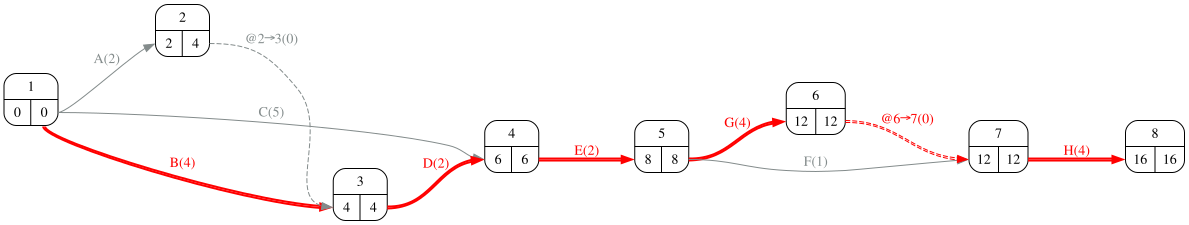

In [8]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-pert
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Construya el calendario mensual de facturas de las subcontratas y calcule cuánto gana el contratista (en valor actual, a su coste de capital) pagando a 90 días en lugar de a 30, y cuánto pagando a 60.  

In [10]:
#| tbl-cap: "Facturación mensual de las subcontratas (k€)"
#| label: tbl-facturas
factura.round(2).to_frame('factura').T

mes,1,2,3,4
factura,144.0,76.0,110.0,110.0


In [11]:
tabla = pd.DataFrame({dias: {'valor actual para el contratista': valor_actual(dias, m_c),
                             'valor actual para las subcontratas': valor_actual(dias, m_s)} for dias in (30, 60, 90)}).T
tabla.index.name = 'días de pago'
tabla['ganancia del contratista frente a 30'] = tabla.loc[30, 'valor actual para el contratista'] - tabla['valor actual para el contratista']
tabla['pérdida de las subcontratas frente a 30'] = tabla.loc[30, 'valor actual para las subcontratas'] - tabla['valor actual para las subcontratas']
tabla['neto conjunto'] = tabla['ganancia del contratista frente a 30'] - tabla['pérdida de las subcontratas frente a 30']
tabla.round(2)

,valor actual para el contratista,valor actual para las subcontratas,ganancia del contratista frente a 30,pérdida de las subcontratas frente a 30,neto conjunto
días de pago,,,,,
30,430.46,419.77,0.00,0.00,0.00
60,427.71,414.02,2.75,5.75,-3.00
90,424.97,408.35,5.49,11.42,-5.94


In [12]:
Markdown(f'''Pagar a 90 días en vez de a 30 vale **{tabla.loc[90, "ganancia del contratista frente a 30"]:.2f} k€** para el contratista (a 60 días, {tabla.loc[60, "ganancia del contratista frente a 30"]:.2f} k€).''')

Pagar a 90 días en vez de a 30 vale **5.49 k€** para el contratista (a 60 días, 2.75 k€).

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Calcule lo que pierden las subcontratas (en valor actual, a su coste de financiación) en cada caso y el resultado neto para el conjunto. ¿Por qué no es un juego de suma cero?  

In [14]:
Markdown(f'''Las subcontratas pierden **{tabla.loc[90, "pérdida de las subcontratas frente a 30"]:.2f} k€** a 90 días ({tabla.loc[60, "pérdida de las subcontratas frente a 30"]:.2f} a 60): más de lo que gana el contratista, porque se financian más caro ({k_subcontratas:.0%} frente a {k_contratista:.0%}). El neto conjunto es **{tabla.loc[90, "neto conjunto"]:.2f} k€**: el aplazamiento destruye valor; sólo lo traslada, con pérdida, de quien se financia barato a quien se financia caro.''')

Las subcontratas pierden **11.42 k€** a 90 días (5.75 a 60): más de lo que gana el contratista, porque se financian más caro (18% frente a 8%). El neto conjunto es **-5.94 k€**: el aplazamiento destruye valor; sólo lo traslada, con pérdida, de quien se financia barato a quien se financia caro.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. (B) Según la norma de referencia, ¿es legal pagar a 90 días? ¿Y a 60? ¿Qué criterio incumple, en cada caso, la propuesta tal como está formulada («si alguna protesta, siempre hay otra que acepta»)?  

**Norma.** Entre empresas el plazo de pago es de 30 días salvo pacto, y el pacto no puede superar los 60 (Ley 3/2004, art. 4): **90 días es ilegal**, aunque la subcontrata lo acepte; 60 es legal si se pacta. **C5.** La propuesta obtiene 5.5 k€ trasladando a las subcontratas un coste mayor (11.4 k€) que no han aceptado libremente («siempre hay otra que acepta» describe una imposición, no un acuerdo). **C10.** Negociar de buena fe el plazo (a 60, con un precio que lo compense) es legítimo; imponerlo con la amenaza de sustituir al que proteste, no.

In [16]:
preguntas_test = [
    ('El plazo máximo de pago entre empresas que admite la Ley 3/2004 por pacto es…', ['60 días', '30 días', '90 días', 'el que acepte el proveedor'],
     'Art. 4: 30 por defecto; por pacto, nunca más de 60.'),
    ('Aplazar el pago a proveedores que se financian más caro que el contratista…', ['destruye valor en el conjunto', 'es neutro: lo que uno gana lo pierde el otro', 'crea valor', 'no tiene efecto financiero'],
     'El contratista gana menos de lo que pierden las subcontratas.'),
    ('«Si alguna protesta, siempre hay otra que acepta» describe…', ['una imposición: C5 y C10', 'una negociación de buena fe', 'una reserva declarada', 'un conflicto de interés'],
     'Se traslada un coste a quien no lo ha aceptado libremente.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — pago a subcontratistas')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
from pmule import muestra_test
muestra_test(preguntas_test)

$CATEGORY: Ética 19 — pago a subcontratistas

::Ética 19 — pago a subcontratistas P1::El plazo máximo de pago entre empresas que admite la Ley 3/2004 por pacto es… {=60 días ~30 días ~90 días ~el que acepte el proveedor ####Art. 4: 30 por defecto; por pacto, nunca más de 60.}

::Ética 19 — pago a subcontratistas P2::Aplazar el pago a proveedores que se financian más caro que el contratista… {~no tiene efecto financiero =destruye valor en el conjunto ~crea valor ~es neutro: lo que uno gana lo pierde el otro ####El contratista gana menos de lo que pierden las subcontratas.}

::Ética 19 — pago a subcontratistas P3::«Si alguna protesta, siempre hay otra que acepta» describe… {~un conflicto de interés =una imposición: C5 y C10 ~una negociación de buena fe ~una reserva declarada ####Se traslada un coste a quien no lo ha aceptado libremente.}



## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. (C) ¿Qué plazo de pago propondría y cómo lo justificaría ante el director financiero? Aplique la rúbrica.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Propuesta defendible: pagar a 30 (o pactar 60 a cambio de un precio que compense a la subcontrata: su coste de financiación a 60 es 5.8 k€, frente a 2.8 k€ de ganancia nuestra, así que no hay precio que convenga a los dos: el aplazamiento no crea valor que repartir). Al director financiero: la cifra del apartado 1 es pequeña, la del apartado 2 es mayor y la sanción y la reputación con los proveedores no están en su cuenta. Prueba de reversibilidad: ¿aceptaría la empresa que el cliente le pagara a 90?